In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [4]:
filename = './test_networks/horses_combined.txt'
G = nx.read_edgelist(filename)

In [5]:
len(G)

236

In [6]:
2 * G.number_of_edges() / G.number_of_nodes()

5.423728813559322

In [7]:
for m_size in [2,3,5,6,7,10,11]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+2)

2  k_max:  9
3  k_max:  6
5  k_max:  5
6  k_max:  5
7  k_max:  4
10  k_max:  4
11  k_max:  4


# Init Fitter

In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9,
        'triangle':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.087366
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.048304


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 640},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 1891},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 816},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 2554},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 755},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 7236},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 5386},
 {'name': 'four_loop

# Grid Search

In [10]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,9]},
                {'m': 3,  'k': [1,6]},
                {'m': 5,  'k': [1,5]},
                {'m': 6,  'k': [1,5]},
                {'m': 7,  'k': [1,4]},
                {'m': 10, 'k': [1,4]},
                {'m': 11, 'k': [1,4]}],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-02-25 14:48:49,749] A new study created in memory with name: no-name-fda45be1-30b3-4554-bd78-d2a6eea23b42


Grid Search requires 8 trials...


[I 2025-02-25 14:48:59,233] Trial 0 finished with value: 8.508674326736394 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 8.508674326736394.
[I 2025-02-25 14:49:08,453] Trial 1 finished with value: 8.034089060454875 and parameters: {'m': 2, 'k': 3}. Best is trial 1 with value: 8.034089060454875.
[I 2025-02-25 14:49:18,072] Trial 2 finished with value: 9.154647202786965 and parameters: {'m': 2, 'k': 2}. Best is trial 1 with value: 8.034089060454875.
[I 2025-02-25 14:49:27,906] Trial 3 finished with value: 9.076641050260168 and parameters: {'m': 2, 'k': 8}. Best is trial 1 with value: 8.034089060454875.
[I 2025-02-25 14:49:36,055] Trial 4 finished with value: 8.269398059623969 and parameters: {'m': 2, 'k': 4}. Best is trial 1 with value: 8.034089060454875.
[I 2025-02-25 14:49:45,862] Trial 5 finished with value: 9.407538160208071 and parameters: {'m': 2, 'k': 1}. Best is trial 1 with value: 8.034089060454875.
[I 2025-02-25 14:49:54,625] Trial 6 finished with value: 6.82457

Grid Search requires 5 trials...


[I 2025-02-25 14:50:23,298] Trial 0 finished with value: 7.660390857384879 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 7.660390857384879.
[I 2025-02-25 14:50:42,743] Trial 1 finished with value: 8.614363272101263 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 7.660390857384879.
[I 2025-02-25 14:51:02,299] Trial 2 finished with value: 9.380481051472124 and parameters: {'m': 3, 'k': 2}. Best is trial 0 with value: 7.660390857384879.
[I 2025-02-25 14:51:18,719] Trial 3 finished with value: 7.895881466374692 and parameters: {'m': 3, 'k': 4}. Best is trial 0 with value: 7.660390857384879.
[I 2025-02-25 14:51:39,744] Trial 4 finished with value: 9.869979197627384 and parameters: {'m': 3, 'k': 5}. Best is trial 0 with value: 7.660390857384879.
[I 2025-02-25 14:51:39,745] A new study created in memory with name: no-name-95d8758d-f215-481f-a85c-0c687a65e638


Grid Search requires 4 trials...


... (6 outputs left out)

[I 2025-02-25 15:16:07,665] Trial 0 finished with value: 9.005158620919454 and parameters: {'m': 10, 'k': 3}. Best is trial 0 with value: 9.005158620919454.
[I 2025-02-25 15:19:20,132] Trial 1 finished with value: 8.334866624485883 and parameters: {'m': 10, 'k': 2}. Best is trial 1 with value: 8.334866624485883.
[I 2025-02-25 15:21:53,827] Trial 2 finished with value: 10.182597827725813 and parameters: {'m': 10, 'k': 1}. Best is trial 1 with value: 8.334866624485883.
[I 2025-02-25 15:21:53,829] A new study created in memory with name: no-name-28c91c4d-b315-4e7e-9565-53fec4b31826


Grid Search requires 3 trials...


[I 2025-02-25 15:41:21,870] Trial 0 finished with value: 9.100447055047786 and parameters: {'m': 11, 'k': 3}. Best is trial 0 with value: 9.100447055047786.
[I 2025-02-25 15:46:21,494] Trial 1 finished with value: 8.558854044744026 and parameters: {'m': 11, 'k': 2}. Best is trial 1 with value: 8.558854044744026.
[I 2025-02-25 15:49:46,259] Trial 2 finished with value: 11.015677098895548 and parameters: {'m': 11, 'k': 1}. Best is trial 1 with value: 8.558854044744026.


Best parameters:  {'m': 2, 'k': 5}
Best energy:  10.566099551406904
Best KL-divergence:  0.05212916188677759
Best KLD augumented energy: 6.806896719226357
Best P matrix:
 [[0.99996399 0.02597413]
 [0.02597413 0.77342797]]
Best l vector:
 [0.54574206 0.45425794]


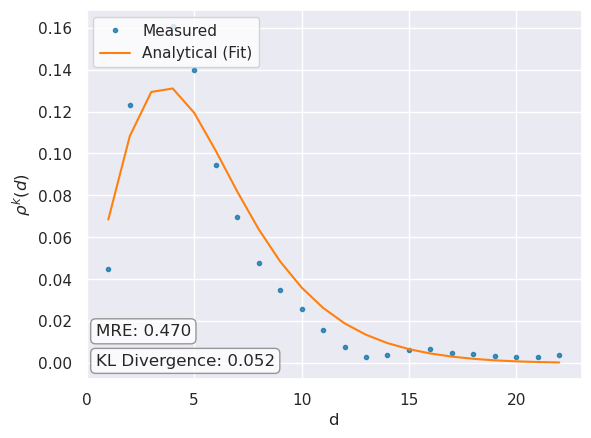

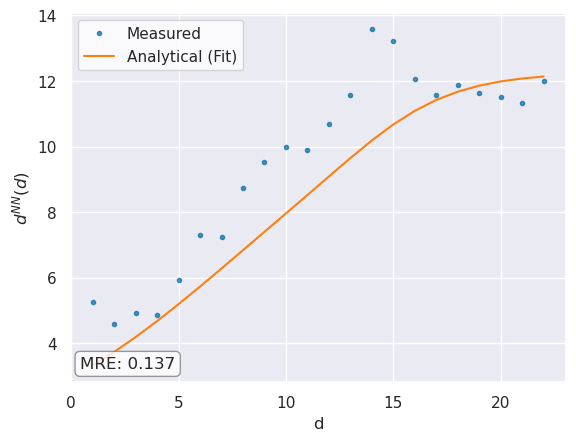

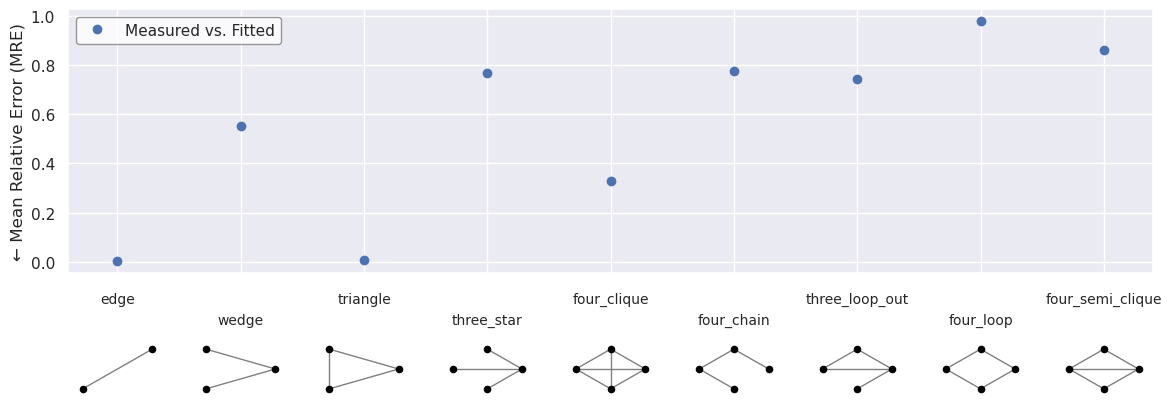

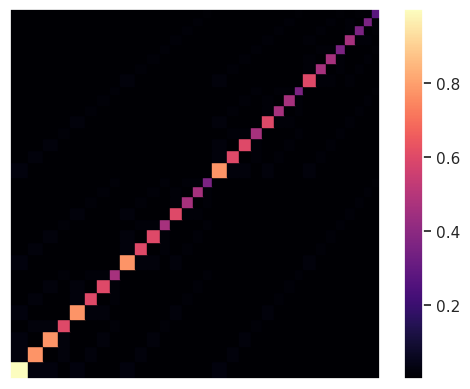

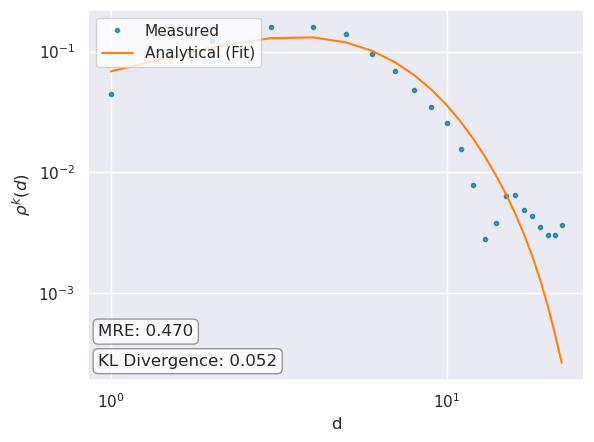

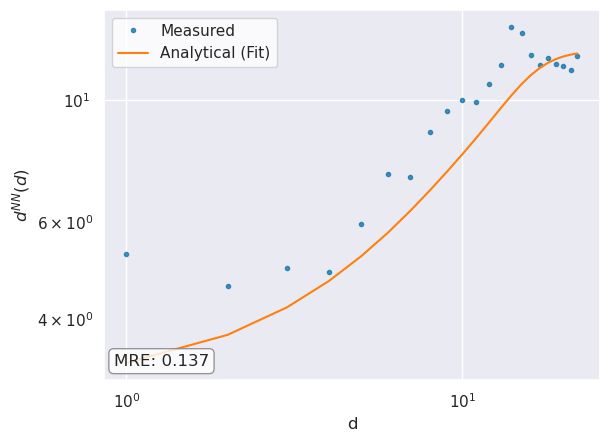

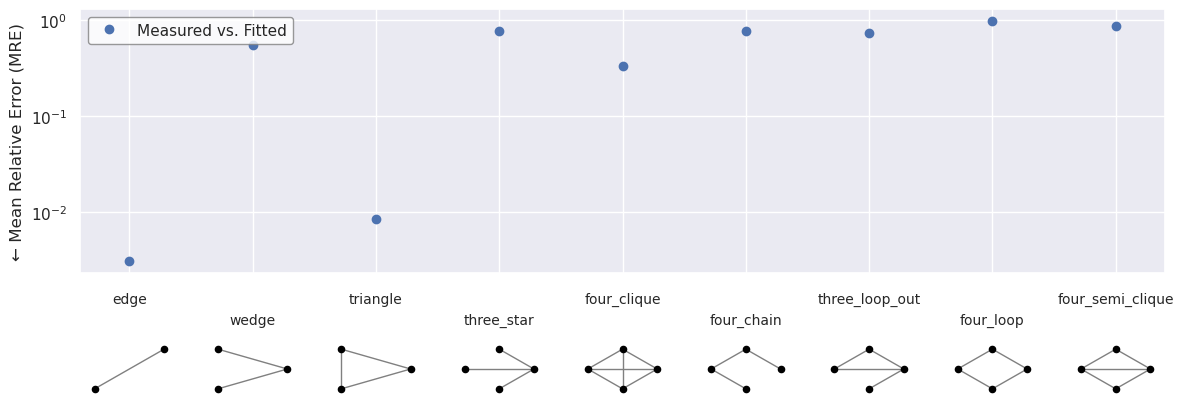

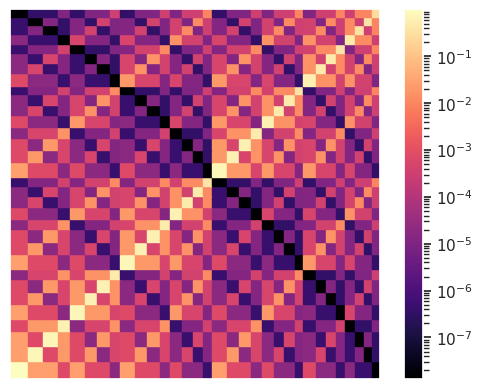

In [11]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_combined_log_plot.pdf"
)

# Bootstrapping Stability

In [12]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'median'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [04:09<00:00,  8.31s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.222302
Energy = 10.53 (9.96, 11.35)
l = [0.59 (0.55, 0.64), 0.41 (0.36, 0.45)]
P = [
[0.94 (0.87, 1.00), 0.02 (0.00, 0.07)],

[0.02 (0.00, 0.07), 0.80 (0.62, 0.92)]
]


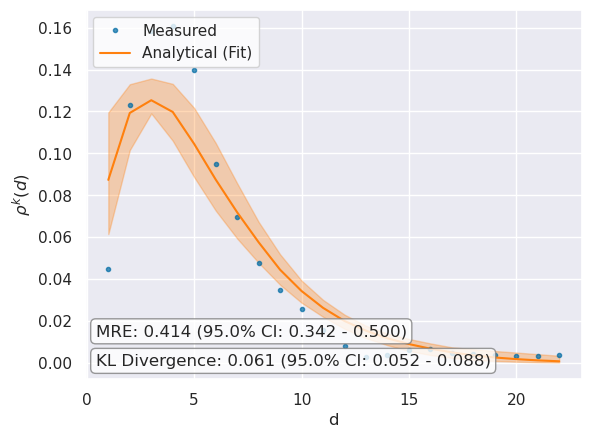

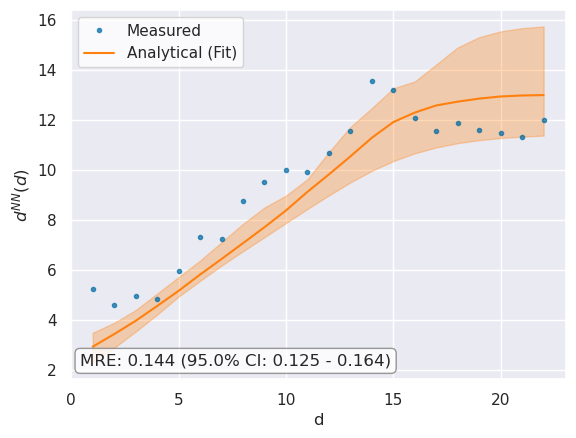

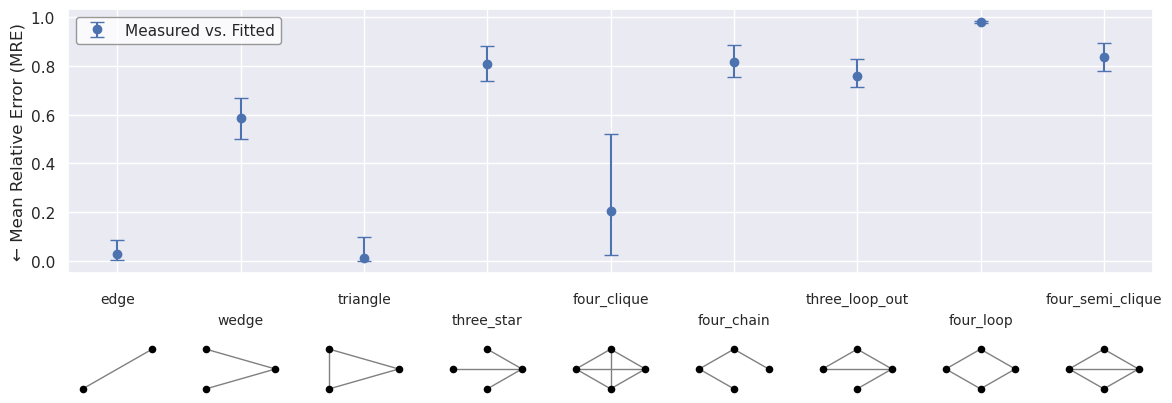

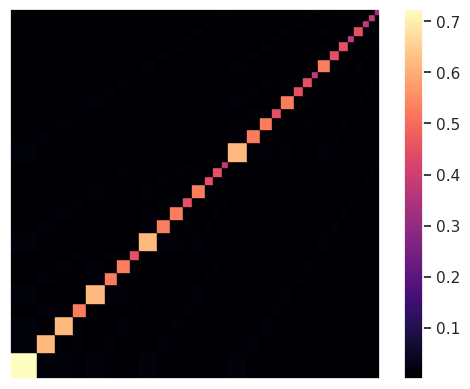

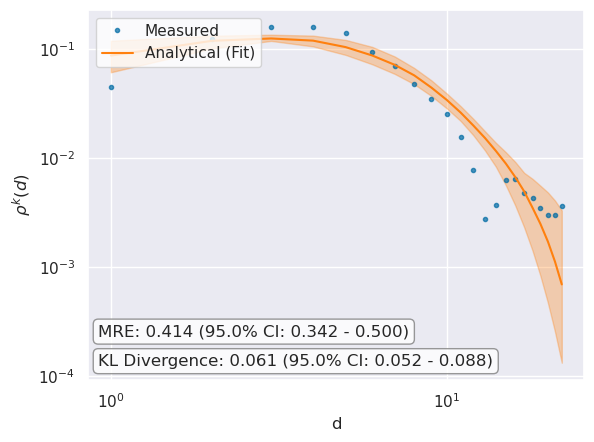

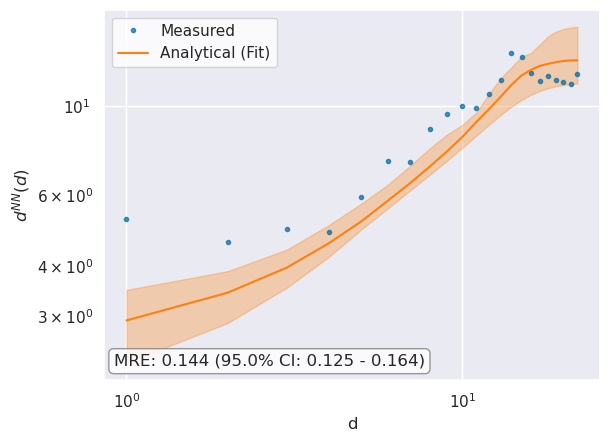

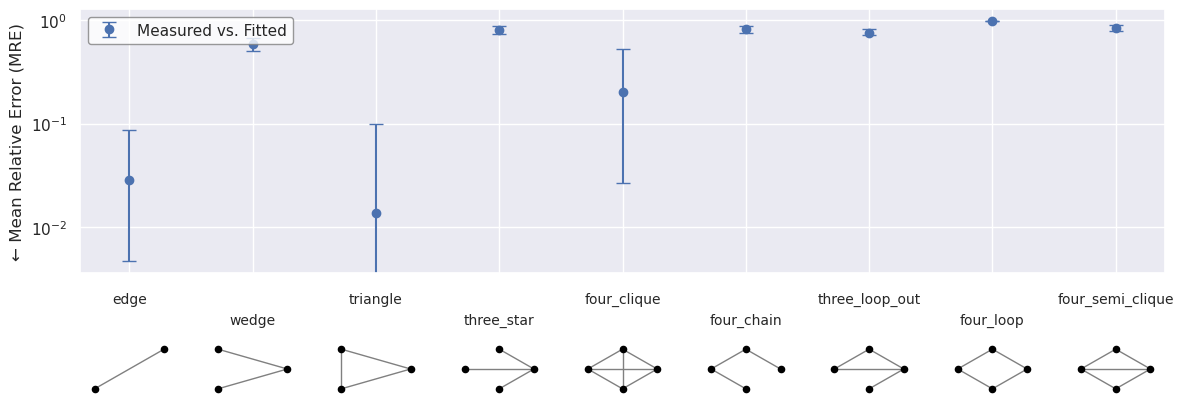

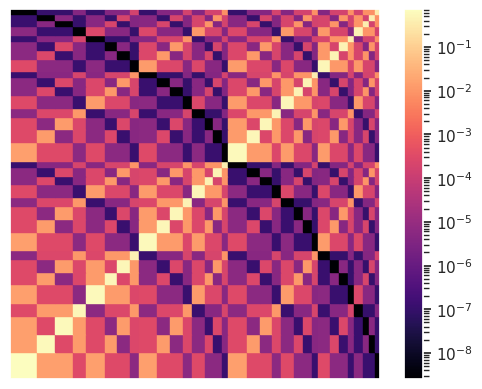

In [13]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_combined_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_combined_log_plot.pdf"
)

In [14]:
mfnf.P

array([[0.93725309, 0.01872391],
       [0.01872391, 0.80066928]])

In [15]:
mfnf.l

array([0.59079692, 0.40920308])

In [16]:
import pickle
with open('./test_networks/horses_combined_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

# Generate Variants

Initializing...
0.003614187240600586
Calculating betweenness...
Done.
Calculating node positions...
Done.


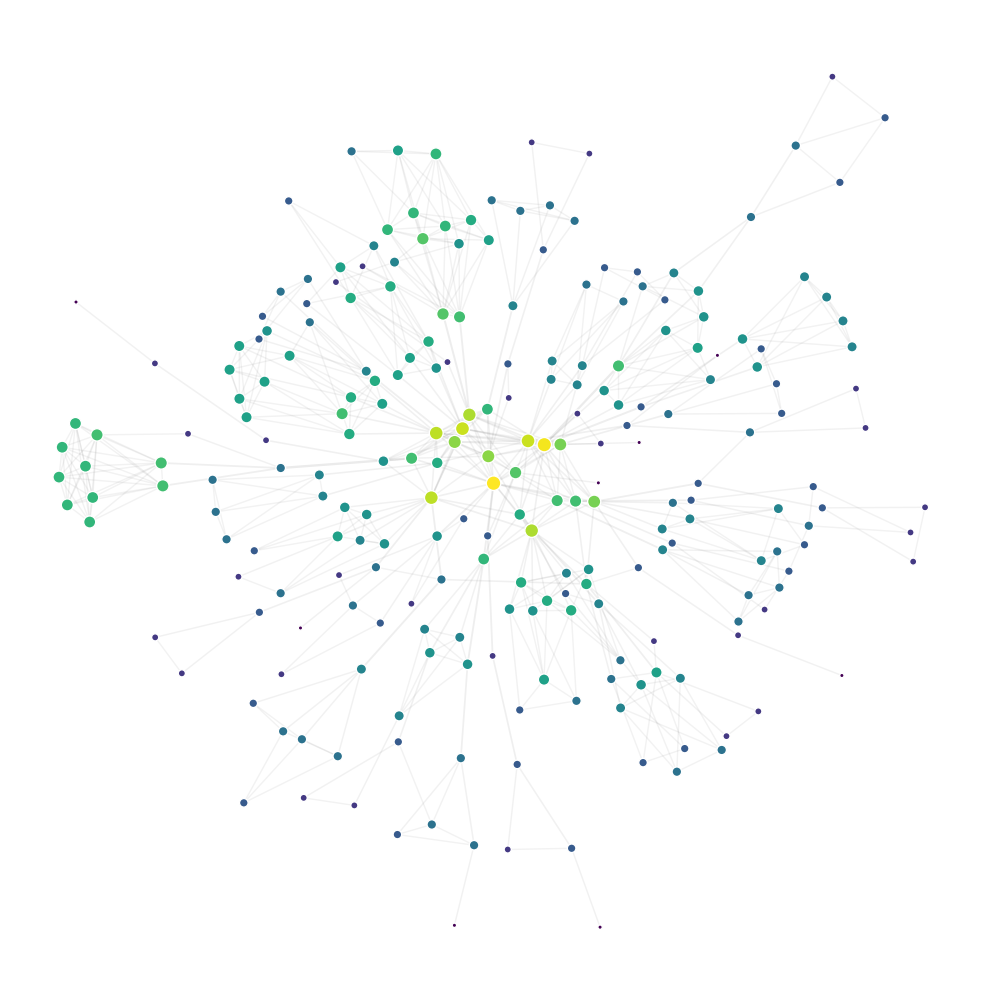

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 127.87it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


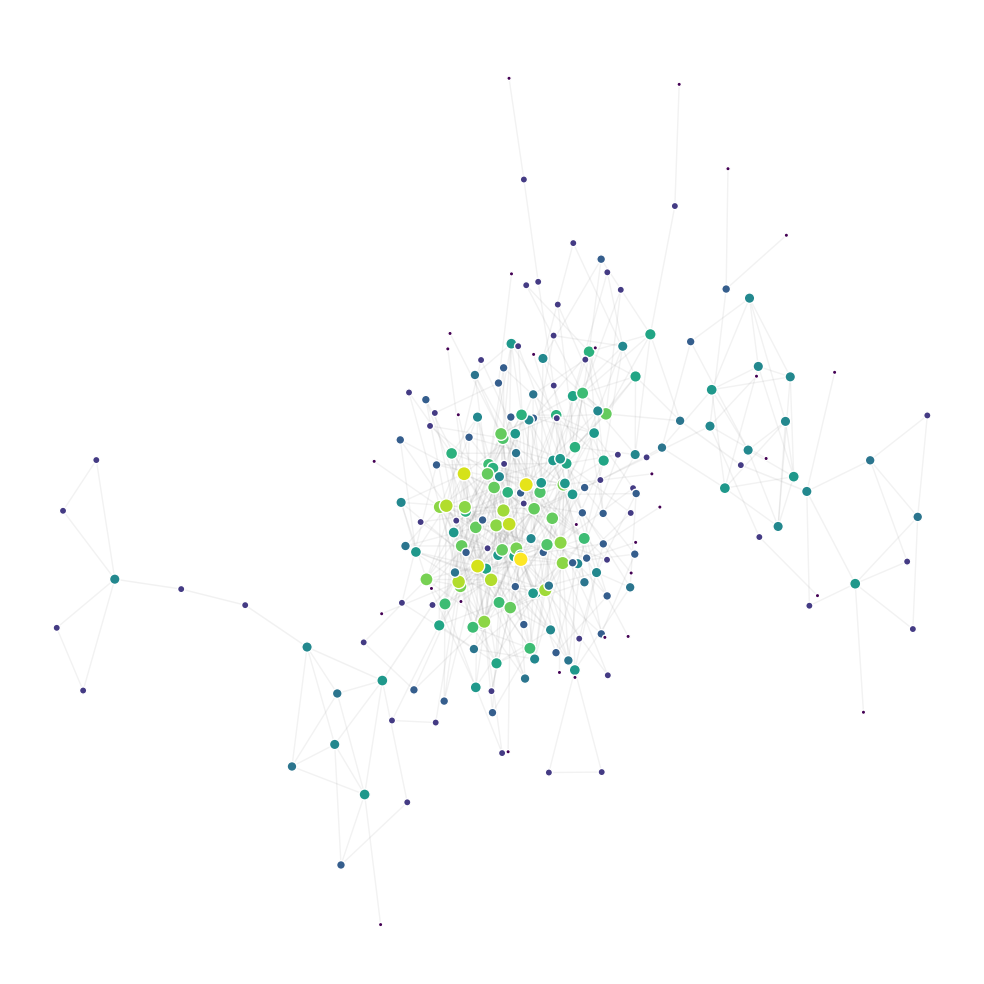

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 115.28it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


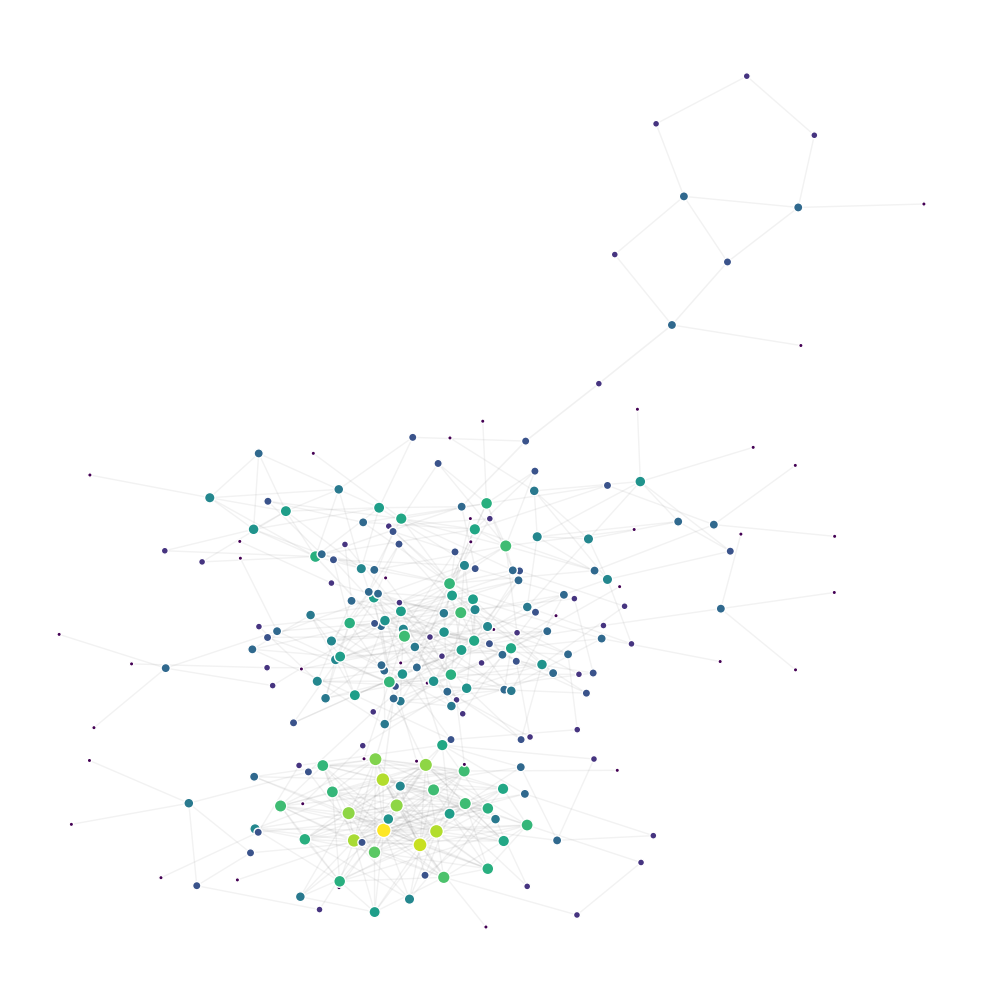

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 144.37it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


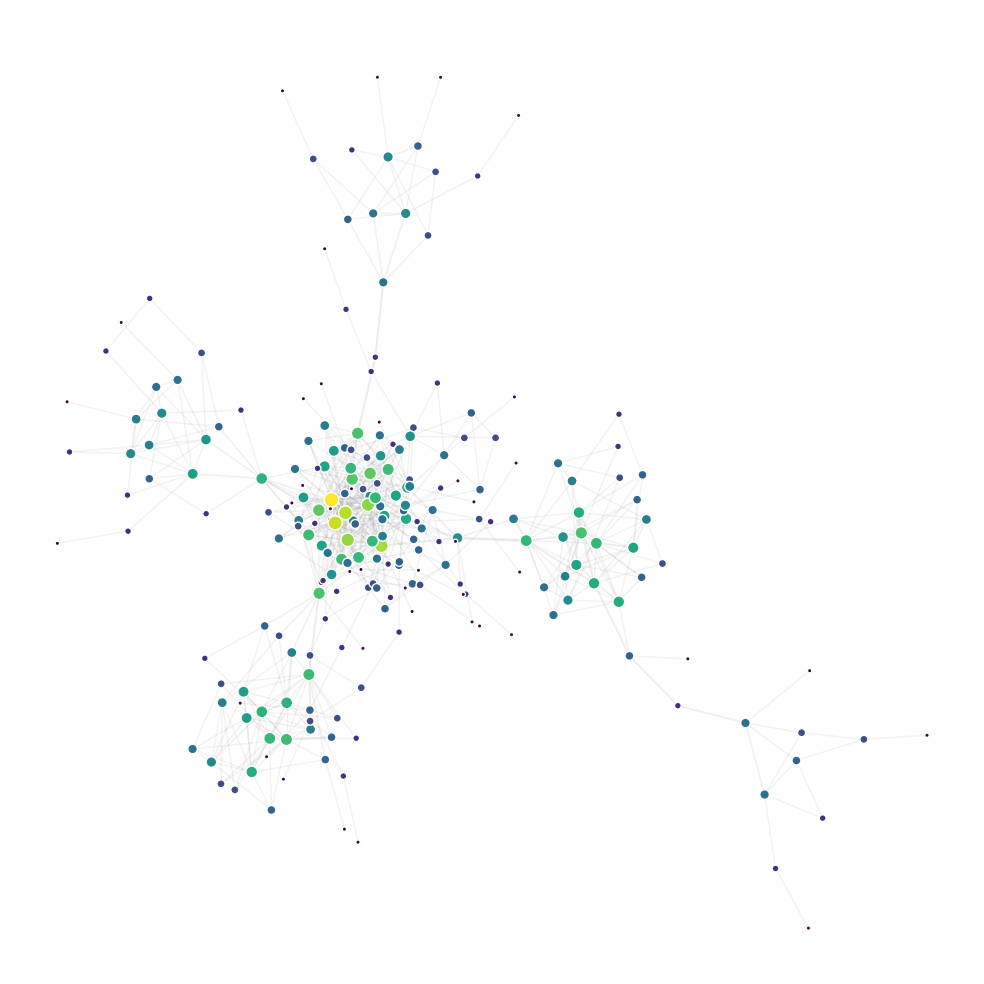

In [16]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/horses_combined_variants.pdf"
    },
    filename = "variant_networks/horses_combined_variants.graphml"
)